In [ ]:
!pip -q install qiskit qiskit-aer matplotlib pylatexenc

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pylatexenc

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

simulator = AerSimulator()

print("Qiskit environment is ready.")

Qiskit environment is ready.


# 3. **The CHSH Game**

## 3.1. What is the CHSH game?

The CHSH game is a two-player game that demonstrates a difference between classical correlations and quantum correlations.

Alice and Bob are separated. They cannot communicate with each other once the game begins.

A referee independently gives each player a random input:

$$
x,y\in\{0,1\}.
$$

Alice returns a bit $a$, and Bob returns a bit $b$.

They win if

$$
\boxed{a\oplus b=x\land y}
$$

where:

- $\oplus$ means XOR, or addition modulo 2.
- $\land$ means AND.

### The complete winning table

| Alice's input \(x\) | Bob's input \(y\) | Winning condition |
|---:|---:|---|
| 0 | 0 | $a=b$ |
| 0 | 1 | $a=b$ |
| 1 | 0 | $a=b$ |
| 1 | 1 | $a\ne b$ |

So they must give the **same output** in the first three cases and **different outputs** in the last case.

The challenge is that Alice and Bob cannot communicate after receiving their inputs.

## 3.2. Can a classical strategy win every round?
Suppose Alice and Bob use the simplest strategy: both always answer zero.

Then

$$
a=0,\qquad b=0.
$$

They win for input pairs $00$, $01$, and $10$, but lose for $11$.

Because all four input pairs are equally likely,

$$
P(\text{win})=\frac{3}{4}=0.75.
$$

More generally, the best classical strategy using shared randomness, but no communication, cannot exceed

$$
\boxed{P_{\mathrm{classical}}\leq \frac{3}{4}}.
$$

This is called the classical bound for the CHSH game.

Why can't a classical deterministic strategy win all four cases? The three conditions requiring equal outputs imply that the output should remain equal across all input changes. But the final condition requires different outputs for $x=y=1$. Those four requirements cannot all be satisfied simultaneously.

### 3.3. Simulate the Classical Strategy

In [ ]:
from itertools import product

def classical_strategy(x, y):
    # Both players always output 0
    return 0, 0

def chsh_wins(x, y, a, b):
    return (a ^ b) == (x & y)

classical_results = []

for x, y in product([0, 1], repeat=2):
    a, b = classical_strategy(x, y)
    win = chsh_wins(x, y, a, b)

    classical_results.append(win)

    print(
        f"x={x}, y={y} | a={a}, b={b} | "
        f"{'WIN' if win else 'LOSE'}"
    )

print("\nClassical winning probability:", np.mean(classical_results))

x=0, y=0 | a=0, b=0 | WIN
x=0, y=1 | a=0, b=0 | WIN
x=1, y=0 | a=0, b=0 | WIN
x=1, y=1 | a=0, b=0 | LOSE

Classical winning probability: 0.75


### 3.4 The Quantum Strategy
Alice and Bob can do better if they share an entangled pair.

They begin with

$$
|\Phi^+\rangle=\frac{|00\rangle+|11\rangle}{\sqrt{2}}.
$$

They measure their qubits using settings determined by their respective inputs.

One convenient choice of observables is

$$
A_0=Z,\qquad A_1=X,
$$

for Alice, and

$$
B_0=\frac{Z+X}{\sqrt{2}},\qquad
B_1=\frac{Z-X}{\sqrt{2}},
$$

for Bob.

Here $X$ and $Z$ are Pauli operators. Each measurement gives an outcome corresponding to a bit $0$ or $1$.

In a Qiskit circuit, standard measurement is measurement in the computational, or $Z$, basis.

- To measure Alice in the $Z$ basis, she does nothing before measurement.
- To measure Alice in the $X$ basis, she applies a Hadamard gate $H$ before measurement.
- Bob uses a $Y$-axis rotation before standard measurement to implement his two measurement settings.

With these choices, the probability of winning is

$$
\boxed{
P_{\mathrm{quantum}}
=
\cos^2\left(\frac{\pi}{8}\right)
=
\frac{2+\sqrt{2}}{4}
\approx 0.8536
}
$$

Thus, the quantum strategy wins approximately \(85.36\%\) of the rounds, compared with the maximum classical value of $75\%$.

**Important:** The advantage comes from the quantum correlations and the chosen measurement settings, not from communication between Alice and Bob during the game.

### 3.5. Build a CHSH circuit for each input pair

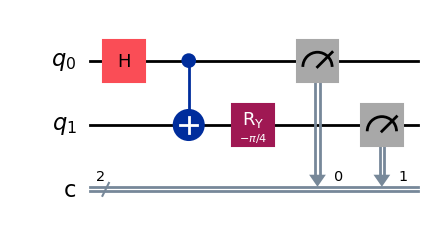

In [ ]:
def chsh_circuit(x, y):
    """
    Construct the CHSH quantum strategy for fixed inputs x and y.

    q0: Alice
    q1: Bob
    c0: Alice's output bit
    c1: Bob's output bit
    """

    qc = QuantumCircuit(2, 2)

    # Step 1: Prepare the shared Bell state
    qc.h(0)
    qc.cx(0, 1)

    # Step 2: Alice's measurement setting
    # x=0 -> Z measurement
    # x=1 -> X measurement, implemented using H then Z measurement
    if x == 1:
        qc.h(0)

    # Step 3: Bob's measurement setting
    # y=0 -> (Z + X)/sqrt(2)
    # y=1 -> (Z - X)/sqrt(2)
    if y == 0:
        qc.ry(-np.pi / 4, 1)
    else:
        qc.ry(np.pi / 4, 1)

    # Step 4: Measure both qubits
    qc.measure(0, 0)
    qc.measure(1, 1)

    return qc


# Display the circuit for x=0, y=0
qc_chsh = chsh_circuit(0, 0)

display(qc_chsh.draw("mpl"))

### Why are the rotations on Bob's qubit different?

Bob's measurement setting depends on his input $y$.

For $y=0$, the rotation is

$$
R_y\left(-\frac{\pi}{4}\right),
$$

and for $y=1$, it is

$$
R_y\left(+\frac{\pi}{4}\right).
$$

The rotation is applied immediately before the standard computational-basis measurement. It changes which observable is effectively measured.

Alice and Bob choose these rotations based only on their own inputs. Neither needs to know the other's input.

### 3.6. Run the CHSH game

In [ ]:
shots_per_input = 5000

quantum_results = []
detailed_results = []

for x, y in product([0, 1], repeat=2):

    qc = chsh_circuit(x, y)

    result = simulator.run(
        transpile(qc, simulator),
        shots=shots_per_input
    ).result()

    counts = result.get_counts()

    wins = 0
    total = sum(counts.values())

    for bitstring, count in counts.items():
        # Qiskit displays c1c0, which is Bob's bit followed by Alice's bit.
        b = int(bitstring[-2])
        a = int(bitstring[-1])

        if chsh_wins(x, y, a, b):
            wins += count

    win_rate = wins / total
    quantum_results.append(win_rate)

    detailed_results.append({
        "x": x,
        "y": y,
        "counts": counts,
        "win_rate": win_rate
    })

    print(
        f"x={x}, y={y} | "
        f"counts={counts} | "
        f"win rate={win_rate:.4f}"
    )

quantum_win_rate = np.mean(quantum_results)

theoretical_quantum = (2 + np.sqrt(2)) / 4
classical_bound = 0.75

print("\n--------------------------------")
print(f"Simulated quantum win rate: {quantum_win_rate:.4f}")
print(f"Theoretical quantum value:  {theoretical_quantum:.4f}")
print(f"Classical upper bound:      {classical_bound:.4f}")
print("--------------------------------")

x=0, y=0 | counts={'01': 365, '11': 2153, '00': 2124, '10': 358} | win rate=0.8554
x=0, y=1 | counts={'01': 338, '11': 2155, '10': 395, '00': 2112} | win rate=0.8534
x=1, y=0 | counts={'11': 2104, '01': 400, '10': 337, '00': 2159} | win rate=0.8526
x=1, y=1 | counts={'11': 359, '01': 2117, '00': 372, '10': 2152} | win rate=0.8538

--------------------------------
Simulated quantum win rate: 0.8538
Theoretical quantum value:  0.8536
Classical upper bound:      0.7500
--------------------------------


### 3.7. Compare classical and quantum performance

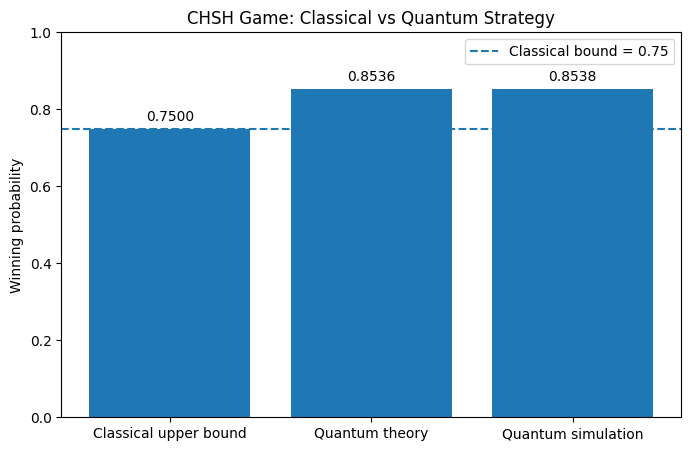

In [ ]:
labels = [
    "Classical upper bound",
    "Quantum theory",
    "Quantum simulation"
]

values = [
    0.75,
    theoretical_quantum,
    quantum_win_rate
]

plt.figure(figsize=(8, 5))
bars = plt.bar(labels, values)

plt.ylim(0, 1)
plt.ylabel("Winning probability")
plt.title("CHSH Game: Classical vs Quantum Strategy")
plt.axhline(
    y=0.75,
    linestyle="--",
    label="Classical bound = 0.75"
)

plt.legend()

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.4f}",
        ha="center"
    )

plt.show()

### How to explain the graph

The classical upper bound is $0.75$. The ideal quantum strategy predicts a winning probability of approximately $0.8536$.

The simulated result should be close to the theoretical value, but it will usually differ slightly because the number of shots is finite.

The gap is the important result:

$$
\boxed{0.8536>0.75}
$$

This is the central lesson of the CHSH game: entanglement can produce correlations that outperform every classical strategy under the game's assumptions.

A violation observed in a real experiment requires careful control of experimental errors and loopholes. An ideal simulator illustrates the mathematical prediction; it does not, by itself, establish an experimental Bell inequality violation.

---
---

# **Conclusion**

## 17. Final comparison

All three topics involve entanglement, but their goals are different.

| Topic | Main purpose | How entanglement is used |
|---|---|---|
| Quantum teleportation | Transfer an unknown quantum state | Shared entanglement plus two classical bits |
| Superdense coding | Communicate two classical bits by sending one qubit | Shared entanglement plus a transmitted qubit |
| CHSH game | Demonstrate stronger-than-classical correlations | Shared entanglement plus local measurement choices |

### The three main lessons

**Quantum teleportation**

$$
\text{Shared entanglement}
+
\text{2 classical bits}
\longrightarrow
\text{quantum-state transfer}.
$$

**Superdense coding**

$$
\text{Shared entanglement}
+
\text{1 transmitted qubit}
\longrightarrow
\text{2 classical bits}.
$$

**CHSH game**

$$
P_{\mathrm{classical}}\leq 0.75,
\qquad
P_{\mathrm{quantum}}\approx0.8536.
$$

The shared idea is that entanglement is a useful resource in quantum information, but each protocol exploits it in a different way.